In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/wine_data.csv',header=None, usecols=[0,1,3])
df.columns = ['Class label','Alcohol','Melic Acid']

In [5]:
df.head()

,Class label,Alcohol,Melic Acid
0,1,14.23,2.43
1,1,13.20,2.14
2,1,13.16,2.67
3,1,14.37,2.50
4,1,13.24,2.87


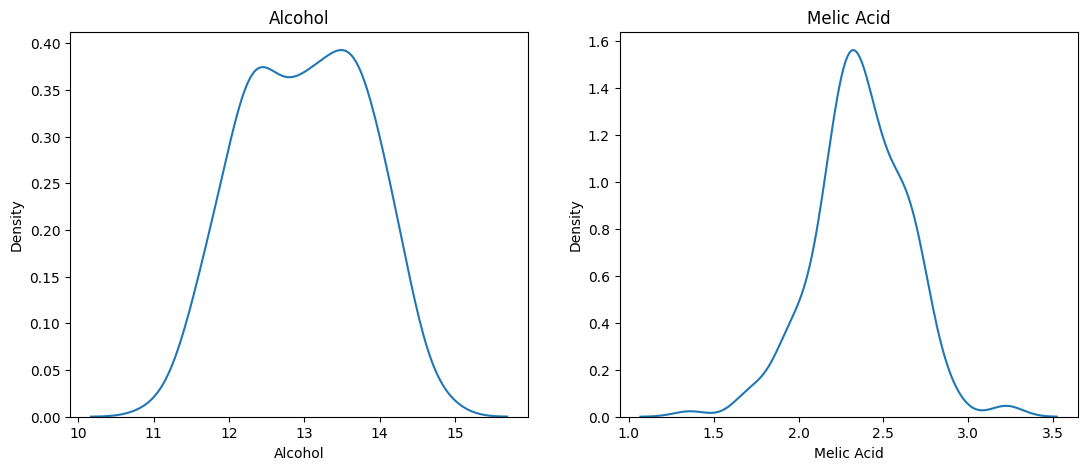

In [6]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(13,5))

ax1.set_title('Alcohol')
sns.kdeplot(df['Alcohol'], ax = ax1)

ax2.set_title('Melic Acid')
sns.kdeplot(df['Melic Acid'], ax = ax2)

plt.show()

<Axes: xlabel='Alcohol', ylabel='Melic Acid'>

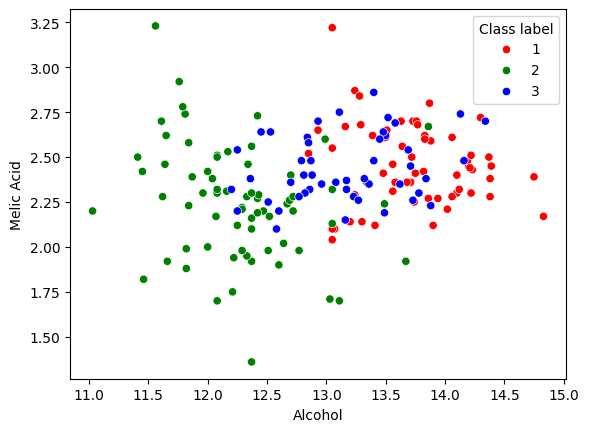

In [7]:
sns.scatterplot(x=df['Alcohol'],y=df['Melic Acid'], hue=df['Class label'], palette = ['red','green','blue'])

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df.drop('Class label', axis=1), df['Class label'], train_size=0.3,random_state=0)
X_train.shape, X_test.shape

((53, 2), (125, 2))

In [11]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [16]:
import numpy as np 

np.round(X_train_scaled.describe(),1)

,Alcohol,Melic Acid
count,53.0,53.0
mean,0.6,0.4
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.3
50%,0.6,0.4
75%,0.8,0.6
max,1.0,1.0


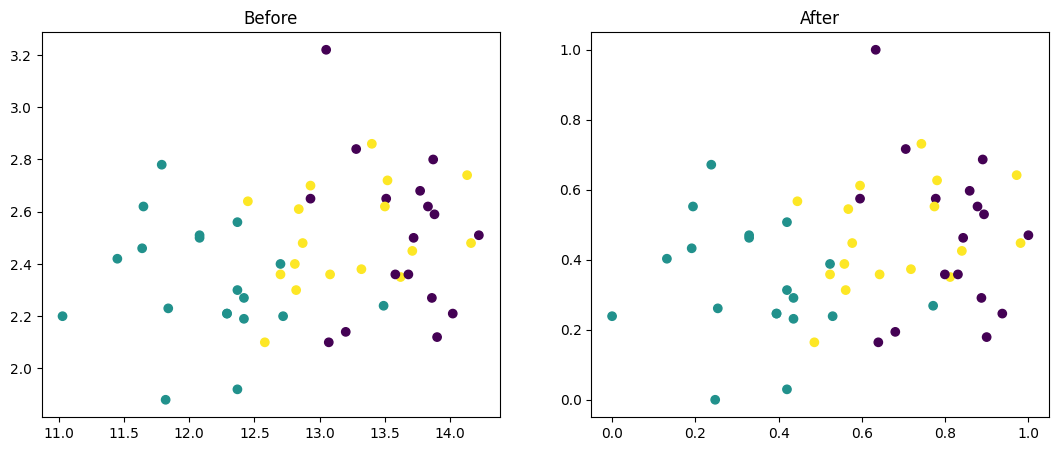

In [20]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(13,5))

ax1.set_title('Before')
ax2.set_title('After')

ax1.scatter(X_train['Alcohol'],X_train['Melic Acid'], c=y_train)
ax2.scatter(X_train_scaled['Alcohol'], X_train_scaled['Melic Acid'], c=y_train)

plt.show()

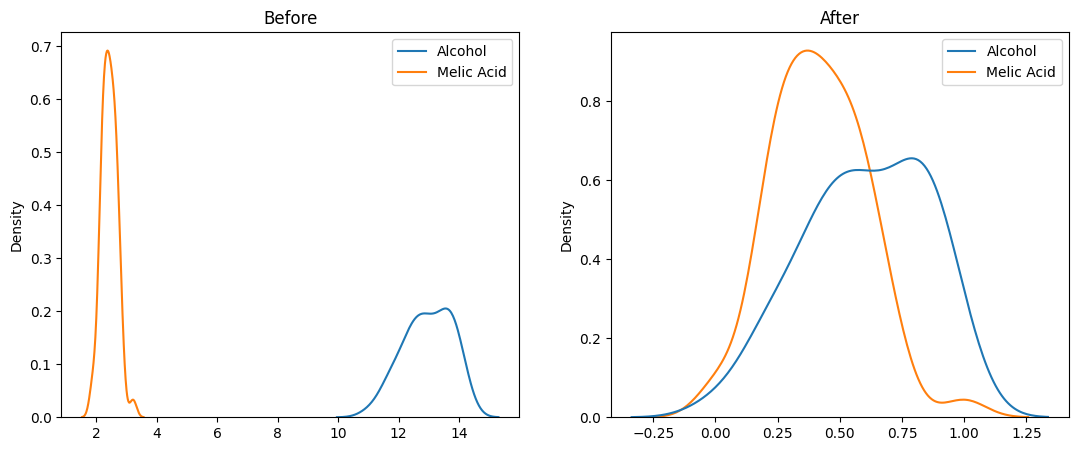

In [22]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(13,5))

ax1.set_title('Before')
ax2.set_title('After')

sns.kdeplot(X_train, ax=ax1)
sns.kdeplot(X_train_scaled, ax=ax2)

plt.show()